# Characteristics Inventory (What We Have vs. What We Need)

This notebook catalogs available characteristics across data sources and highlights
what is still missing to match the paper’s 29‑characteristic set.

Goal:
- Identify available fields in current datasets
- Map them to the paper’s characteristic definitions
- Flag missing items for future sourcing

In [8]:
from pathlib import Path
import pandas as pd

# Base directories
notebook_dir = Path.cwd()
repo_root = notebook_dir.parent
src_data = repo_root / "src" / "data"

src_data

WindowsPath('c:/Users/cat33/OneDrive/ドキュメント/Uchicago/Project Lab/Exponential/CreditTrading/src/data')

In [14]:
# Load column lists for ALL parquet datasets under src/data (no full load needed)
import fastparquet

# Use fastparquet to avoid pyarrow issues
def list_columns(path: Path):
    return fastparquet.ParquetFile(path).columns

parquet_paths = sorted(src_data.rglob("*.parquet"))

columns = {}
failed = []
for path in parquet_paths:
    name = path.relative_to(src_data).as_posix()
    try:
        columns[name] = list_columns(path)
    except Exception as exc:
        failed.append((name, str(exc)))

if failed:
    print("Failed to read schema for:")
    for name, err in failed:
        print(f"- {name}: {err}")

columns

{'datascope_characteristic_eod.parquet': ['RIC',
  'Trade Date',
  'Asset ID',
  'Asset Status',
  'Asset Status Description',
  'Asset SubType',
  'Asset SubType Description',
  'Asset Type',
  'Asset Type Description',
  'Country of Incorporation',
  'Country of Incorporation Description',
  'Currency Code',
  'Currency Code Description',
  'ESMA Standard Market Size Currency Code',
  'Exchange Code',
  'Exchange Description',
  'Instrument ID',
  'Instrument ID Type',
  'Issue PermID',
  'Issuer Name',
  'Issuer OrgID',
  'Issuer PermID',
  'Quote ID',
  'Reference Company',
  'Security Description',
  'Ticker'],
 'datascope_eod_resampled_from_tick_complete.parquet': ['Date-Time',
  '#RIC',
  'Domain',
  'GMT Offset',
  'Ex/Cntrb.ID',
  'Bid Price',
  'Ask Price',
  'Qualifiers',
  'Exch Time',
  'Bid Yld',
  'Ask Yld',
  'ISMA Bid Yld',
  'ISMA Ask Yld',
  'Duration',
  'Mod Durtn',
  'BPV',
  'Convexity',
  'Bench Spd',
  'Swp Spd',
  'Asst Swp Spd',
  'Swap Point',
  'Premium',
 

In [15]:
# Quick view: number of columns per dataset
{k: len(v) for k, v in columns.items()}

{'datascope_characteristic_eod.parquet': 26,
 'datascope_eod_resampled_from_tick_complete.parquet': 45,
 'datascope_eod_us_treasury.parquet': 33,
 'datascope_metadata_eod_resampled_from_tick.parquet': 8,
 'datascope_price_eod.parquet': 13,
 'datascope_price_eod_resampled_from_tick.parquet': 9,
 'datascope_risk_eod_resampled_from_tick.parquet': 14,
 'datascope_yield_eod.parquet': 8,
 'datascope_yield_eod_resampled_from_tick.parquet': 10,
 'fmp_corp_actions.parquet': 24,
 'fmp_enterprise_valuations_ratings.parquet': 41,
 'fmp_hist_financial_statements.parquet': 387,
 'fmp_market_performance.parquet': 21,
 'issuer_reference.parquet': 6,
 'norgate_eod_stock_prices.parquet': 11,
 'wrds_eod_us_treasury_daily.parquet': 16,
 'wrds_eod_us_treasury_monthly.parquet': 17,
 'yieldbook_indicatives.parquet': 85,
 'yieldbook_price_yield.parquet': 71,
 'yieldbook_price_yield_with_labels.parquet': 73}

Saved: c:\Users\cat33\OneDrive\ドキュメント\Uchicago\Project Lab\Exponential\CreditTrading\IPCA_Replication\datamapping/chart1_ric.png


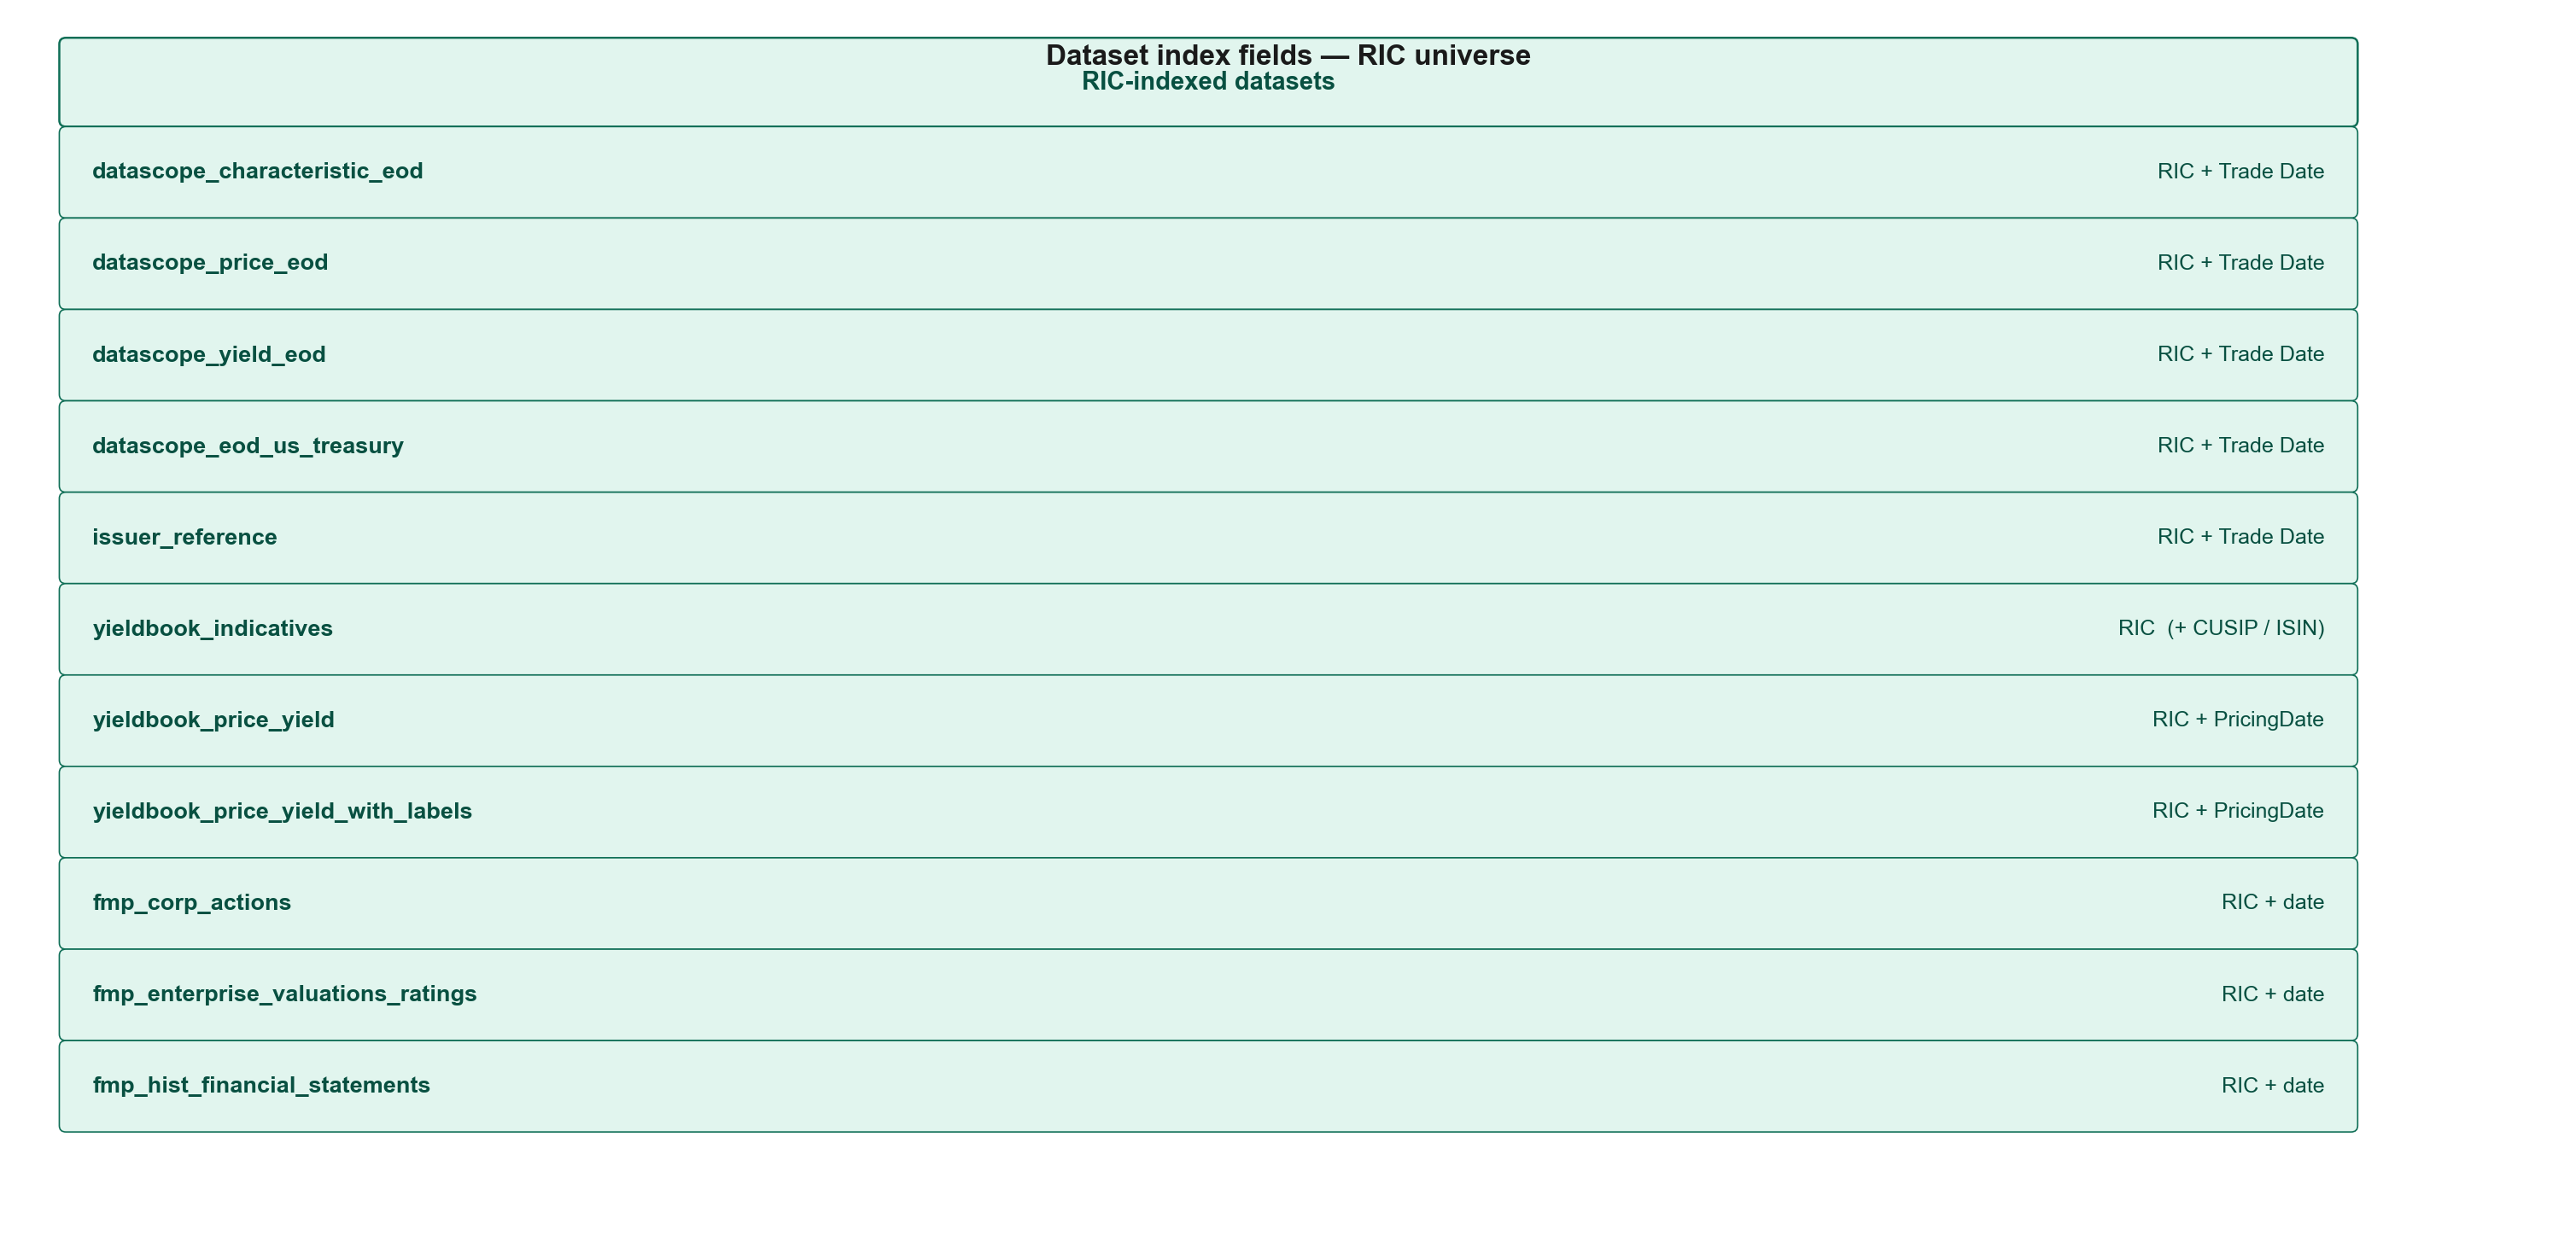

Saved: c:\Users\cat33\OneDrive\ドキュメント\Uchicago\Project Lab\Exponential\CreditTrading\IPCA_Replication\datamapping/chart2_hash_ric.png


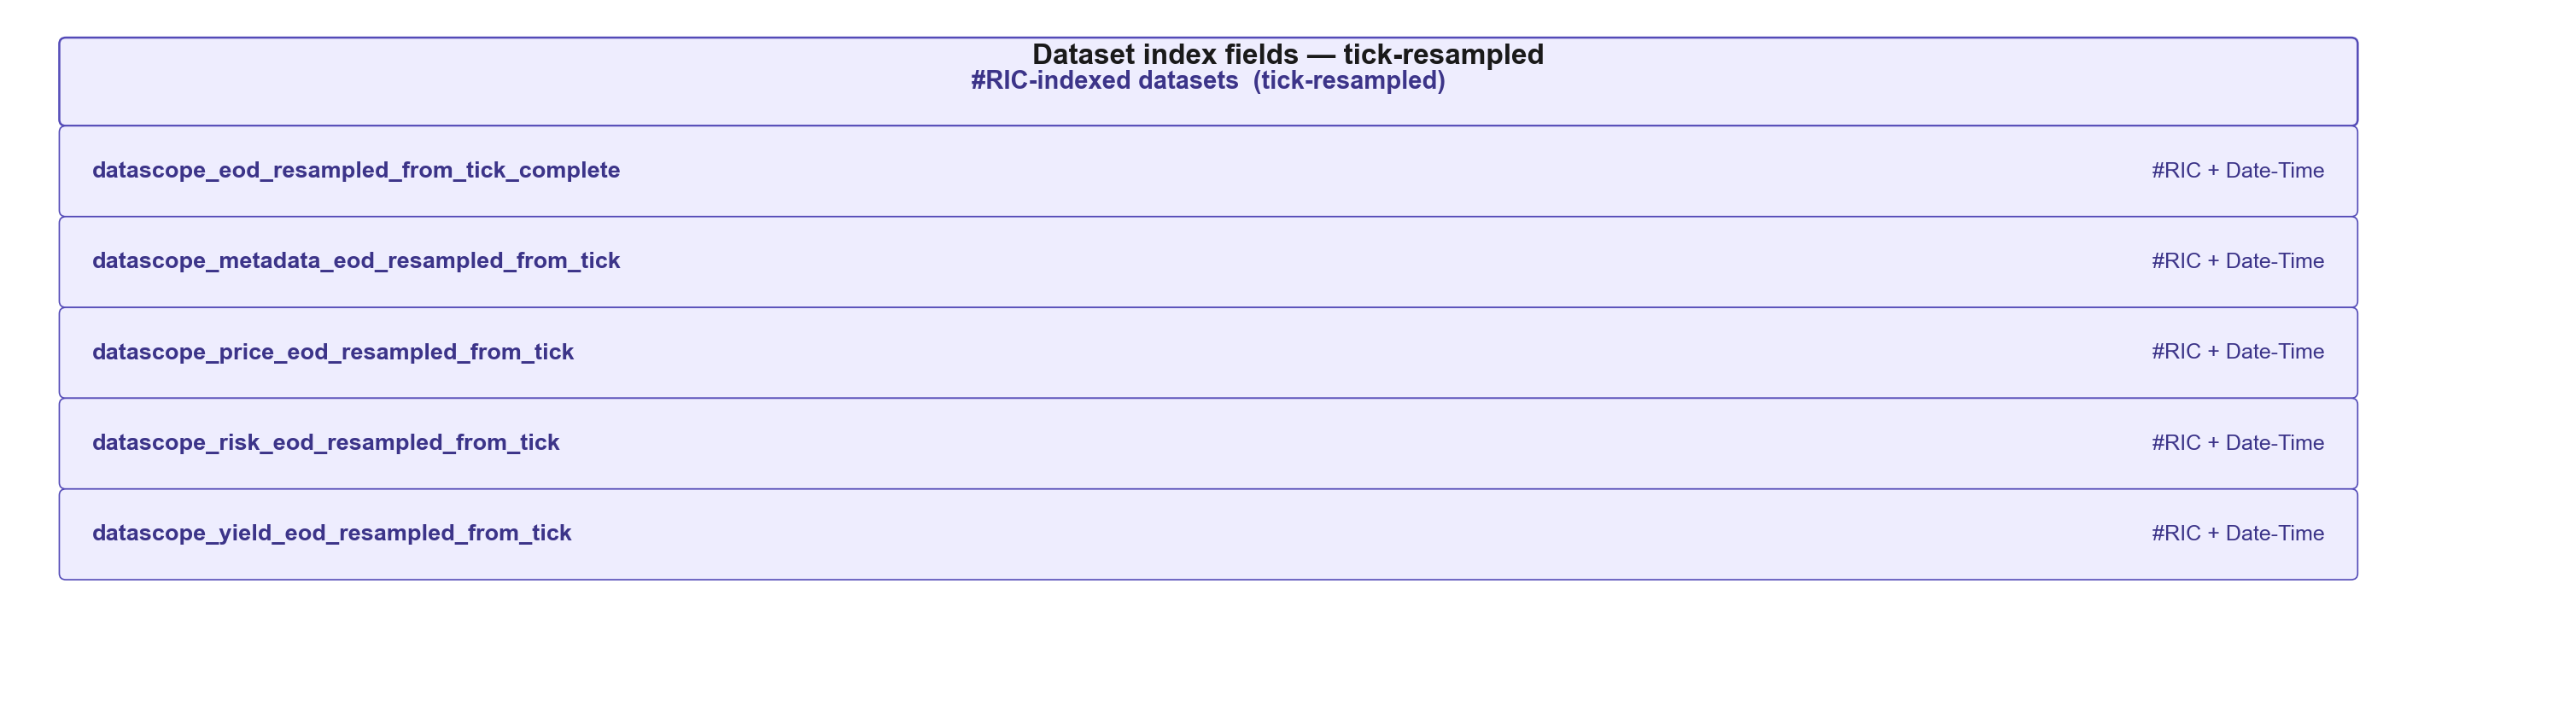

Saved: c:\Users\cat33\OneDrive\ドキュメント\Uchicago\Project Lab\Exponential\CreditTrading\IPCA_Replication\datamapping/_tmp_sect.png


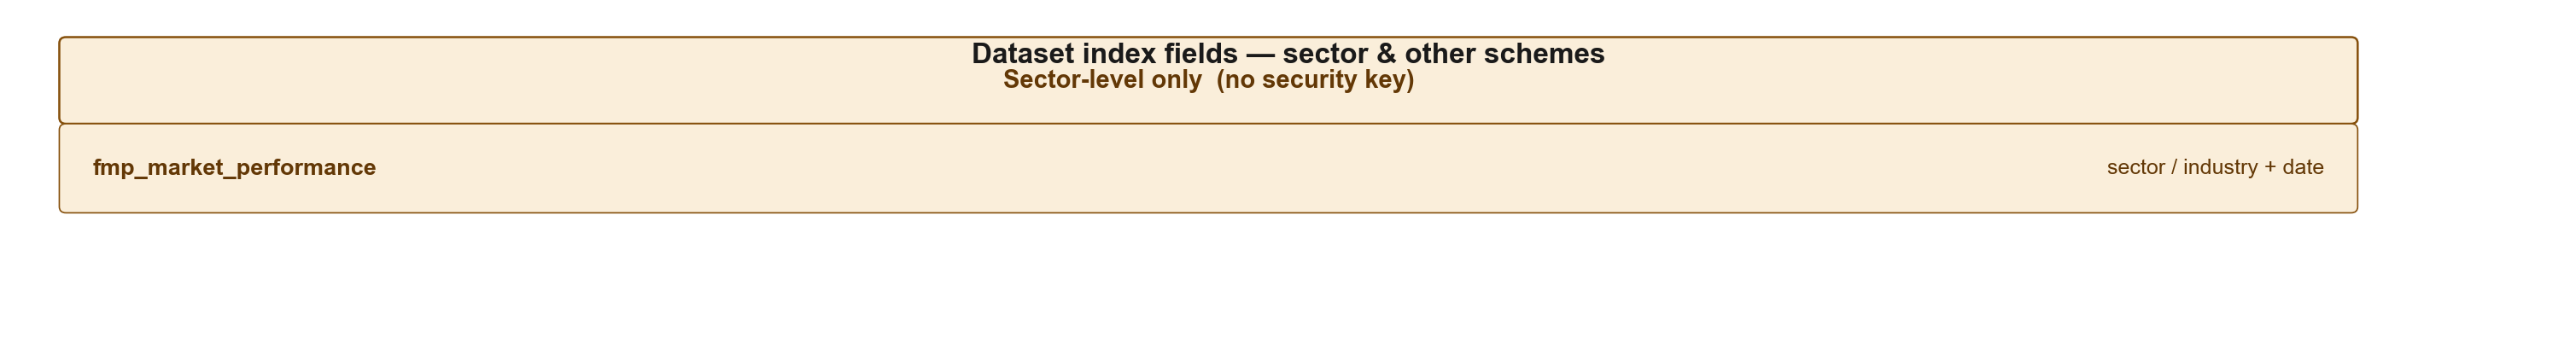

Saved: c:\Users\cat33\OneDrive\ドキュメント\Uchicago\Project Lab\Exponential\CreditTrading\IPCA_Replication\datamapping/_tmp_other.png


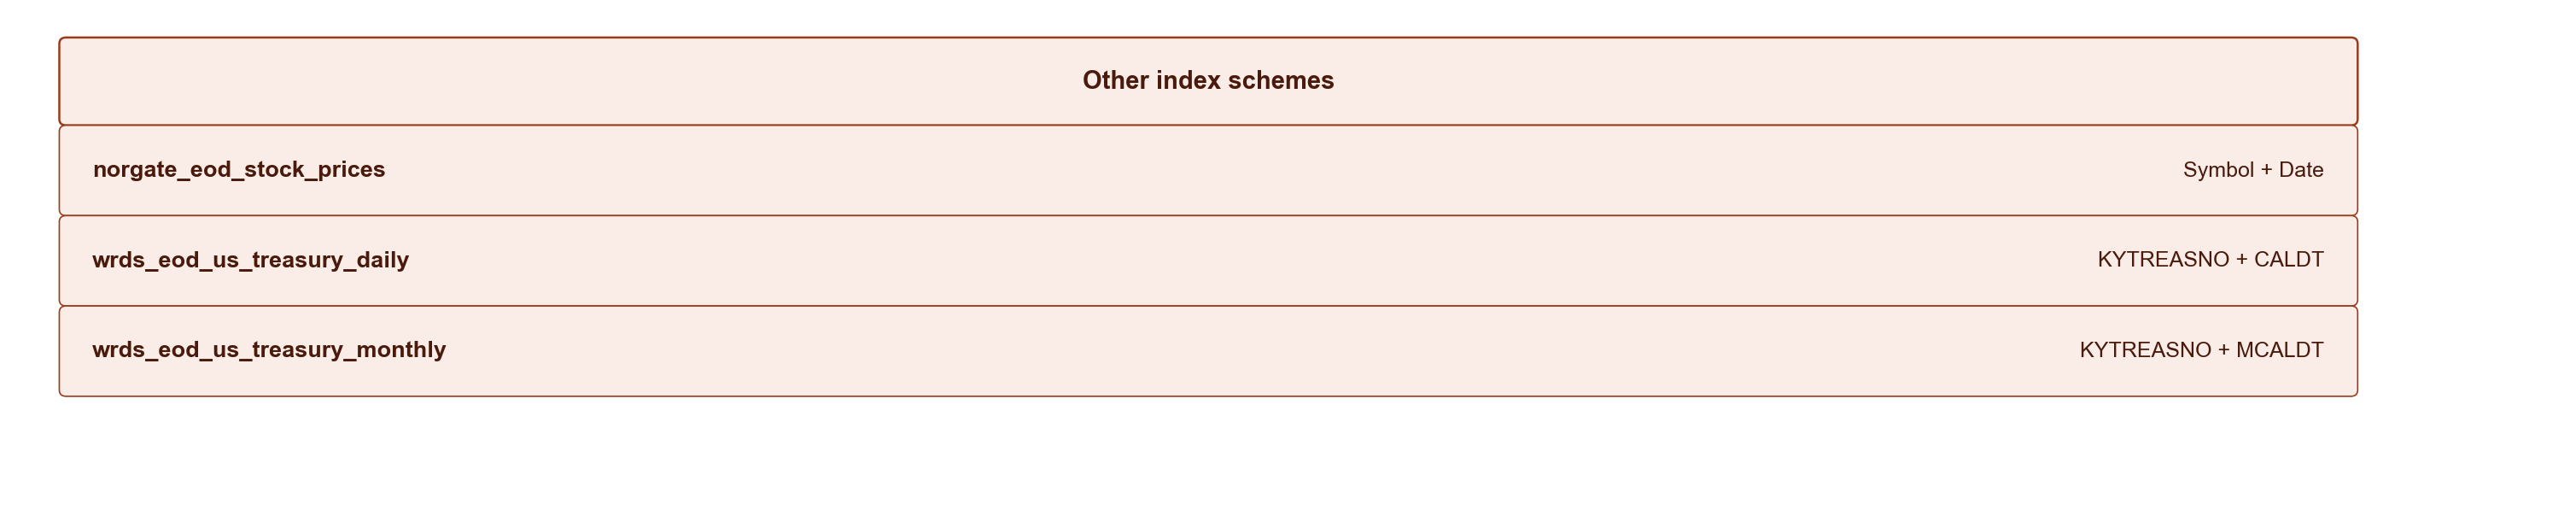

Saved: c:\Users\cat33\OneDrive\ドキュメント\Uchicago\Project Lab\Exponential\CreditTrading\IPCA_Replication\datamapping/chart3_other.png


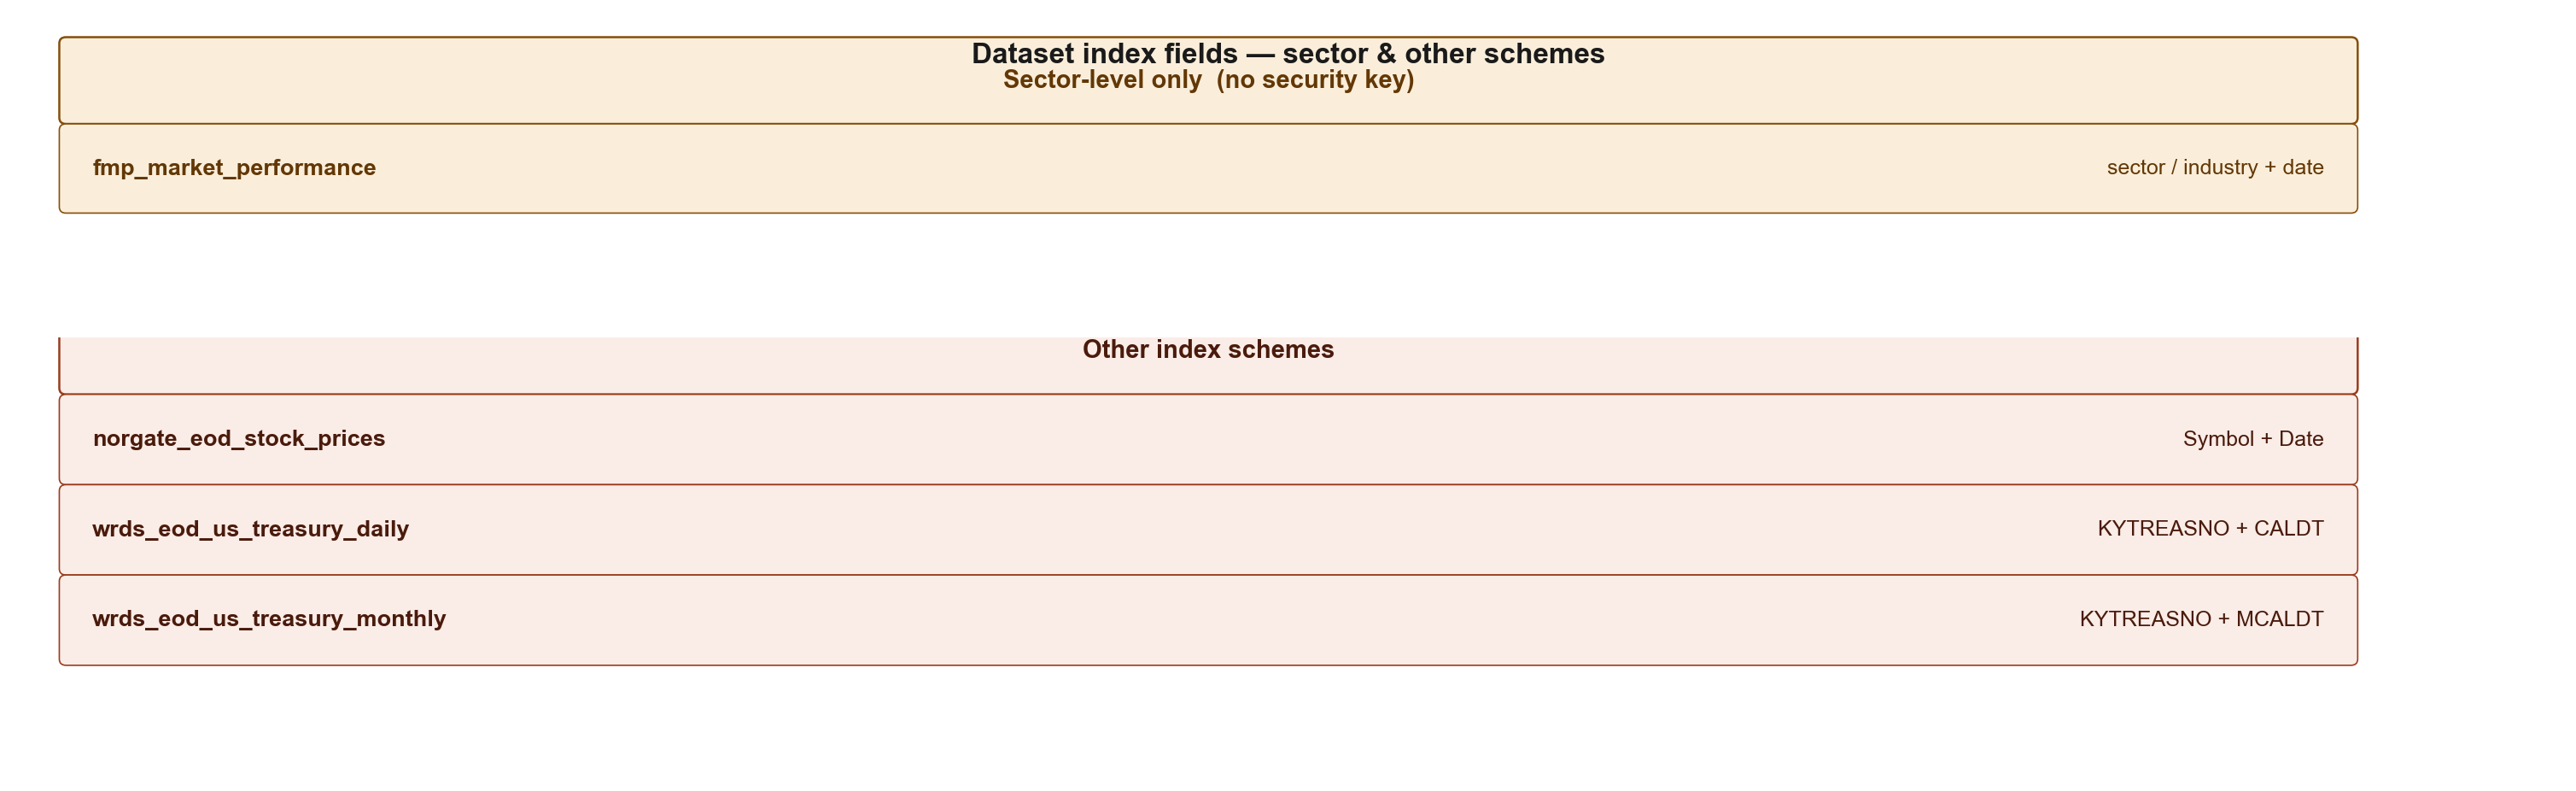

Saved: c:\Users\cat33\OneDrive\ドキュメント\Uchicago\Project Lab\Exponential\CreditTrading\IPCA_Replication\datamapping/chart4_bridge.png


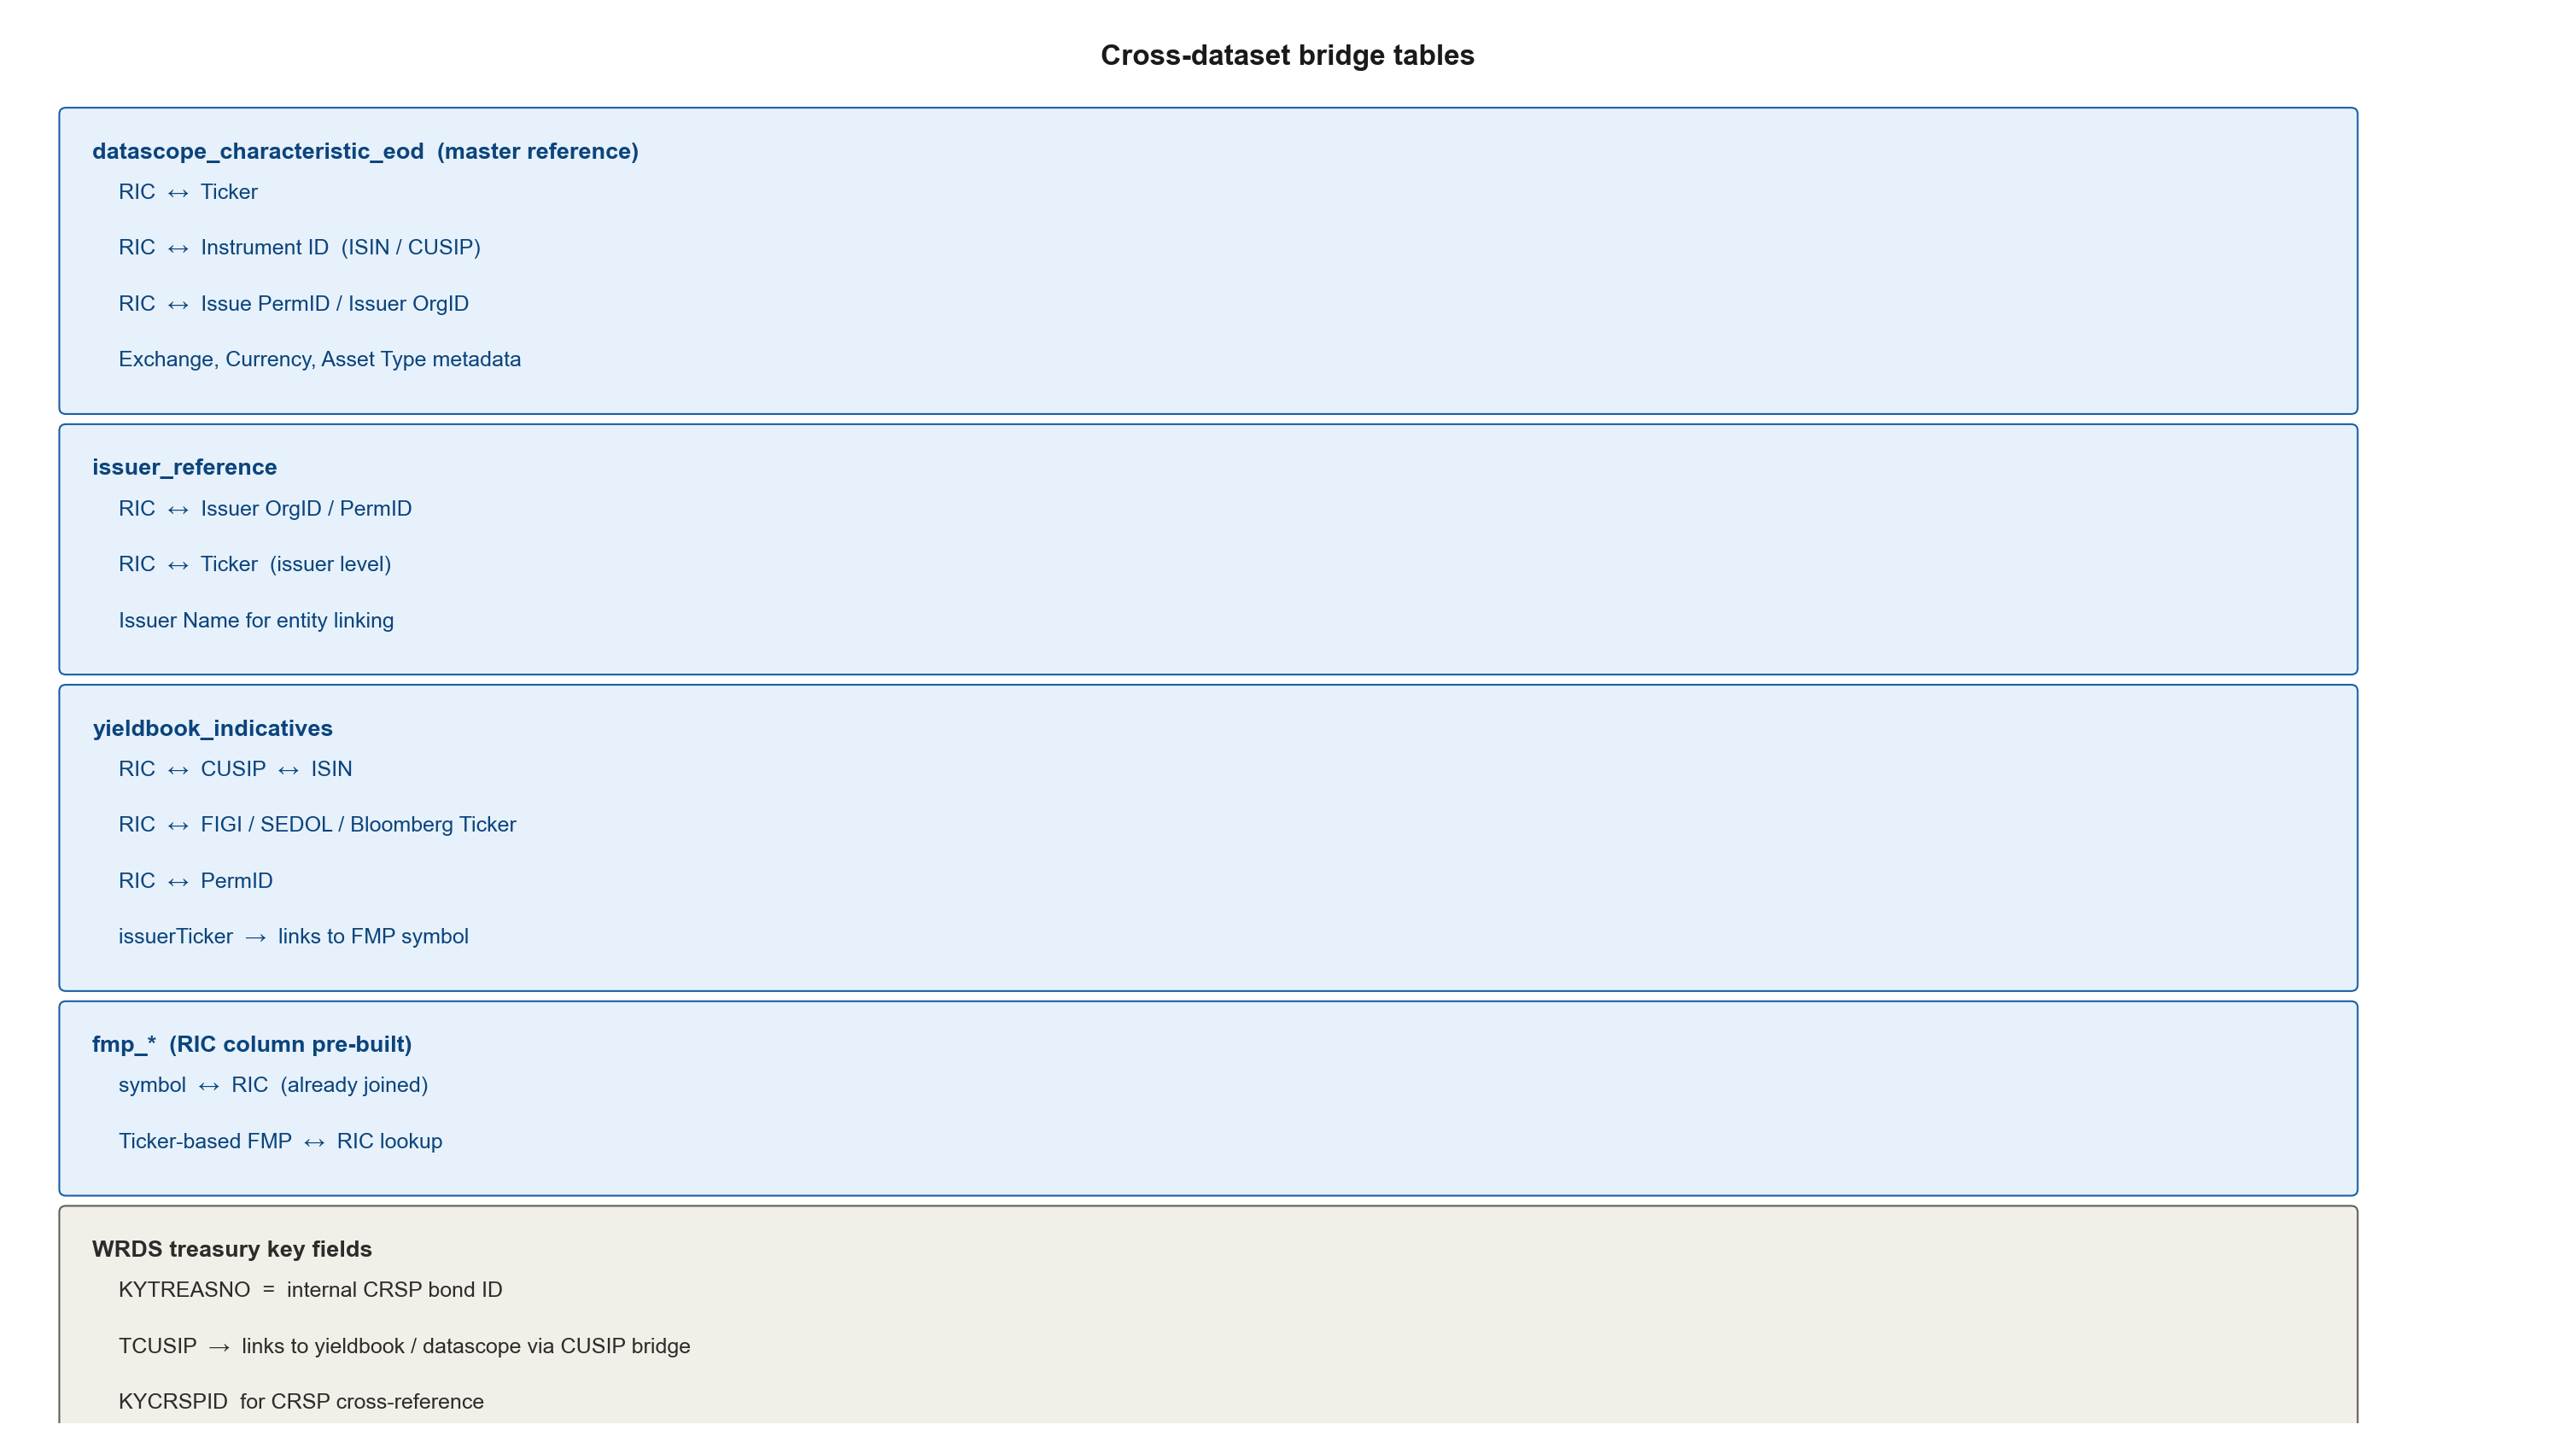

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import matplotlib as mpl
import matplotlib.font_manager as fm
import os
from IPython.display import display, Image as IPImage

def _pick_font():
    available = {f.name for f in fm.fontManager.ttflist}
    for candidate in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']:
        if candidate in available:
            return candidate
    return 'sans-serif'

FONT = _pick_font()
mpl.rcParams['font.family'] = FONT

TEAL_FILL   = '#E1F5EE'; TEAL_EDGE   = '#0F6E56'; TEAL_TEXT   = '#085041'
PURPLE_FILL = '#EEEDFE'; PURPLE_EDGE = '#534AB7'; PURPLE_TEXT = '#3C3489'
AMBER_FILL  = '#FAEEDA'; AMBER_EDGE  = '#854F0B'; AMBER_TEXT  = '#633806'
CORAL_FILL  = '#FAECE7'; CORAL_EDGE  = '#993C1D'; CORAL_TEXT  = '#4A1B0C'
BLUE_FILL   = '#E6F1FB'; BLUE_EDGE   = '#185FA5'; BLUE_TEXT   = '#0C447C'
GRAY_FILL   = '#F1EFE8'; GRAY_EDGE   = '#5F5E5A'; GRAY_TEXT   = '#2C2C2A'

RH  = 0.62   # row height
GAP = 0.10   # gap between rows
LX  = 0.4
LW  = 17.2   # full width for single-column layout


def draw_section(datasets, header_label, header_fill, header_edge, header_tc,
                 row_fill, row_edge, row_tc, title, outpath):
    n = len(datasets)
    fig_h = 1.2 + n * (RH + GAP) + 0.6   # tight fit
    W = 20

    fig, ax = plt.subplots(figsize=(W, fig_h))
    total_y = fig_h
    ax.set_xlim(0, W - 0.8)
    ax.set_ylim(0, total_y)
    ax.axis('off')
    fig.patch.set_facecolor('#ffffff')

    # Figure title
    ax.text((W - 0.8) / 2, total_y - 0.35, title,
            va='center', ha='center', fontsize=16, fontweight='bold',
            color='#1a1a1a', fontfamily=FONT)

    # Section header
    hdr_y = total_y - 0.85
    rect = FancyBboxPatch((LX, hdr_y), LW, 0.60,
                          boxstyle="round,pad=0.05",
                          facecolor=header_fill, edgecolor=header_edge, linewidth=1.2)
    ax.add_patch(rect)
    ax.text(LX + LW / 2, hdr_y + 0.30, header_label,
            va='center', ha='center', fontsize=14, fontweight='bold',
            color=header_tc, fontfamily=FONT)

    # Data rows
    cur_y = hdr_y - (RH + GAP)
    for name, idx in datasets:
        rect = FancyBboxPatch((LX, cur_y), LW, RH,
                              boxstyle="round,pad=0.05",
                              facecolor=row_fill, edgecolor=row_edge, linewidth=0.8)
        ax.add_patch(rect)
        ax.text(LX + 0.20, cur_y + RH / 2, name,
                va='center', ha='left', fontsize=13, fontweight='bold',
                color=row_tc, fontfamily=FONT)
        ax.text(LX + LW - 0.20, cur_y + RH / 2, idx,
                va='center', ha='right', fontsize=12,
                color=row_tc, fontfamily=FONT)
        cur_y -= (RH + GAP)

    plt.tight_layout(pad=0.3)
    plt.savefig(outpath, dpi=150, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"Saved: {outpath}")
    display(IPImage(outpath))


def draw_bridge_section(boxes, title, outpath):
    """boxes: list of (title, lines, fill, edge, tc, sc)"""
    # Estimate height needed
    total_lines = sum(len(b[1]) for b in boxes)
    fig_h = 1.0 + len(boxes) * 0.5 + total_lines * 0.45 + 0.4
    W = 20

    fig, ax = plt.subplots(figsize=(W, fig_h))
    total_y = fig_h
    ax.set_xlim(0, W - 0.8)
    ax.set_ylim(0, total_y)
    ax.axis('off')
    fig.patch.set_facecolor('#ffffff')

    # Figure title
    ax.text((W - 0.8) / 2, total_y - 0.35, title,
            va='center', ha='center', fontsize=16, fontweight='bold',
            color='#1a1a1a', fontfamily=FONT)

    cur_y = total_y - 0.80
    for (btitle, lines, fill, edge, tc, sc) in boxes:
        n = len(lines)
        bh = 0.55 + n * 0.44
        rect = FancyBboxPatch((LX, cur_y - bh), LW, bh,
                              boxstyle="round,pad=0.05",
                              facecolor=fill, edgecolor=edge, linewidth=1.0)
        ax.add_patch(rect)
        # box title
        ax.text(LX + 0.20, cur_y - 0.30, btitle,
                va='center', ha='left', fontsize=13, fontweight='bold',
                color=tc, fontfamily=FONT)
        # lines
        for i, line in enumerate(lines):
            ax.text(LX + 0.40, cur_y - 0.62 - i * 0.44, line,
                    va='center', ha='left', fontsize=12,
                    color=sc, fontfamily=FONT)
        cur_y -= (bh + 0.18)

    plt.tight_layout(pad=0.3)
    plt.savefig(outpath, dpi=150, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"Saved: {outpath}")
    display(IPImage(outpath))


OUT = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'datamapping')
os.makedirs(OUT, exist_ok=True)   # creates the folder if it doesn't exist yet

# ── Chart 1: RIC-indexed datasets ─────────────────────────────────────────────
draw_section(
    datasets=[
        ("datascope_characteristic_eod",           "RIC + Trade Date"),
        ("datascope_price_eod",                    "RIC + Trade Date"),
        ("datascope_yield_eod",                    "RIC + Trade Date"),
        ("datascope_eod_us_treasury",              "RIC + Trade Date"),
        ("issuer_reference",                       "RIC + Trade Date"),
        ("yieldbook_indicatives",                  "RIC  (+ CUSIP / ISIN)"),
        ("yieldbook_price_yield",                  "RIC + PricingDate"),
        ("yieldbook_price_yield_with_labels",      "RIC + PricingDate"),
        ("fmp_corp_actions",                       "RIC + date"),
        ("fmp_enterprise_valuations_ratings",      "RIC + date"),
        ("fmp_hist_financial_statements",          "RIC + date"),
    ],
    header_label="RIC-indexed datasets",
    header_fill=TEAL_FILL, header_edge=TEAL_EDGE, header_tc=TEAL_TEXT,
    row_fill=TEAL_FILL, row_edge=TEAL_EDGE, row_tc=TEAL_TEXT,
    title="Dataset index fields — RIC universe",
    outpath=f'{OUT}/chart1_ric.png'
)

# ── Chart 2: #RIC tick-resampled ──────────────────────────────────────────────
draw_section(
    datasets=[
        ("datascope_eod_resampled_from_tick_complete",   "#RIC + Date-Time"),
        ("datascope_metadata_eod_resampled_from_tick",   "#RIC + Date-Time"),
        ("datascope_price_eod_resampled_from_tick",      "#RIC + Date-Time"),
        ("datascope_risk_eod_resampled_from_tick",       "#RIC + Date-Time"),
        ("datascope_yield_eod_resampled_from_tick",      "#RIC + Date-Time"),
    ],
    header_label="#RIC-indexed datasets  (tick-resampled)",
    header_fill=PURPLE_FILL, header_edge=PURPLE_EDGE, header_tc=PURPLE_TEXT,
    row_fill=PURPLE_FILL, row_edge=PURPLE_EDGE, row_tc=PURPLE_TEXT,
    title="Dataset index fields — tick-resampled",
    outpath=f'{OUT}/chart2_hash_ric.png'
)

# ── Chart 3: Sector + Other ───────────────────────────────────────────────────
draw_section(
    datasets=[
        ("fmp_market_performance",      "sector / industry + date"),
    ],
    header_label="Sector-level only  (no security key)",
    header_fill=AMBER_FILL, header_edge=AMBER_EDGE, header_tc=AMBER_TEXT,
    row_fill=AMBER_FILL, row_edge=AMBER_EDGE, row_tc=AMBER_TEXT,
    title="Dataset index fields — sector & other schemes",
    outpath=f'{OUT}/_tmp_sect.png'
)

draw_section(
    datasets=[
        ("norgate_eod_stock_prices",        "Symbol + Date"),
        ("wrds_eod_us_treasury_daily",      "KYTREASNO + CALDT"),
        ("wrds_eod_us_treasury_monthly",    "KYTREASNO + MCALDT"),
    ],
    header_label="Other index schemes",
    header_fill=CORAL_FILL, header_edge=CORAL_EDGE, header_tc=CORAL_TEXT,
    row_fill=CORAL_FILL, row_edge=CORAL_EDGE, row_tc=CORAL_TEXT,
    title="",   # no title, will be combined
    outpath=f'{OUT}/_tmp_other.png'
)

# Combine sector + other into one figure
from PIL import Image
img1 = Image.open(f'{OUT}/_tmp_sect.png')
img2 = Image.open(f'{OUT}/_tmp_other.png')
# strip title row from img2 (top ~80px)
crop2 = img2.crop((0, 80, img2.width, img2.height))
combined = Image.new('RGB', (max(img1.width, crop2.width),
                              img1.height + crop2.height), (255,255,255))
combined.paste(img1, (0, 0))
combined.paste(crop2, (0, img1.height))
combined.save(f'{OUT}/chart3_other.png', dpi=(150,150))
print(f"Saved: {OUT}/chart3_other.png")
display(IPImage(f'{OUT}/chart3_other.png'))

# ── Chart 4: Bridge tables ────────────────────────────────────────────────────
draw_bridge_section(
    boxes=[
        ("datascope_characteristic_eod  (master reference)",
         ["RIC  ↔  Ticker",
          "RIC  ↔  Instrument ID  (ISIN / CUSIP)",
          "RIC  ↔  Issue PermID / Issuer OrgID",
          "Exchange, Currency, Asset Type metadata"],
         BLUE_FILL, BLUE_EDGE, BLUE_TEXT, BLUE_TEXT),

        ("issuer_reference",
         ["RIC  ↔  Issuer OrgID / PermID",
          "RIC  ↔  Ticker  (issuer level)",
          "Issuer Name for entity linking"],
         BLUE_FILL, BLUE_EDGE, BLUE_TEXT, BLUE_TEXT),

        ("yieldbook_indicatives",
         ["RIC  ↔  CUSIP  ↔  ISIN",
          "RIC  ↔  FIGI / SEDOL / Bloomberg Ticker",
          "RIC  ↔  PermID",
          "issuerTicker  →  links to FMP symbol"],
         BLUE_FILL, BLUE_EDGE, BLUE_TEXT, BLUE_TEXT),

        ("fmp_*  (RIC column pre-built)",
         ["symbol  ↔  RIC  (already joined)",
          "Ticker-based FMP  ↔  RIC lookup"],
         BLUE_FILL, BLUE_EDGE, BLUE_TEXT, BLUE_TEXT),

        ("WRDS treasury key fields",
         ["KYTREASNO  =  internal CRSP bond ID",
          "TCUSIP  →  links to yieldbook / datascope via CUSIP bridge",
          "KYCRSPID  for CRSP cross-reference"],
         GRAY_FILL, GRAY_EDGE, GRAY_TEXT, GRAY_TEXT),
    ],
    title="Cross-dataset bridge tables",
    outpath=f'{OUT}/chart4_bridge.png'
)

# Dataset Join Notes

## Notes

1. **RIC vs #RIC** — Both are Reuters Instrument Codes. The `#` prefix appears only in tick-resampled files and can be treated as equivalent to `RIC` for join purposes (i.e., direct equality match after stripping the prefix if needed).

2. **FMP series** — All FMP datasets (`fmp_corp_actions`, `fmp_enterprise_valuations_ratings`, `fmp_hist_financial_statements`) already contain a `RIC` column, so they can be joined directly to the datascope / yieldbook universe without any additional bridging.

3. **`datascope_characteristic_eod`** is the master reference table. It provides the following cross-identifier mappings:
   - `RIC` → `Ticker`
   - `RIC` → `ISIN` / `CUSIP` (via Instrument ID field)
   - `RIC` → `Issue PermID` / `Issuer OrgID`
   - `RIC` → Exchange, Currency, Asset Type metadata

4. **`fmp_market_performance`** contains no security-level key. It is a sector- and industry-level aggregate dataset only and cannot be joined to individual bond or equity records.

5. **Norgate `Symbol`** is a proprietary identifier. To bring `norgate_eod_stock_prices` into the RIC universe, bridge via the `Ticker` field in `datascope_characteristic_eod`:
   ```
   norgate Symbol  →  datascope Ticker  →  RIC
   ```
   This two-hop join is required before any characteristic that uses Norgate equity price data (e.g., equity momentum, equity volatility) can be merged with bond-level records.

In [10]:
import pandas as pd
from pathlib import Path

src_data = repo_root / "src" / "data"

for f in sorted(src_data.rglob("*.parquet")):
    if "yieldbook_price_yield_with_labels" in f.name:
        continue
    try:
        df = pd.read_parquet(f, engine="fastparquet")
        print(f"\n{'='*60}")
        print(f.name)
        print(f"Shape: {df.shape}")
        print(f"Columns: {df.columns.tolist()}")
        print(df.head(2).to_string())
    except Exception as e:
        print(f"\n[FAIL] {f.name}: {e}")


datascope_characteristic_eod.parquet
Shape: (2193461, 26)
Columns: ['RIC', 'Trade Date', 'Asset ID', 'Asset Status', 'Asset Status Description', 'Asset SubType', 'Asset SubType Description', 'Asset Type', 'Asset Type Description', 'Country of Incorporation', 'Country of Incorporation Description', 'Currency Code', 'Currency Code Description', 'ESMA Standard Market Size Currency Code', 'Exchange Code', 'Exchange Description', 'Instrument ID', 'Instrument ID Type', 'Issue PermID', 'Issuer Name', 'Issuer OrgID', 'Issuer PermID', 'Quote ID', 'Reference Company', 'Security Description', 'Ticker']
          RIC Trade Date            Asset ID Asset Status Asset Status Description Asset SubType Asset SubType Description Asset Type Asset Type Description Country of Incorporation Country of Incorporation Description Currency Code Currency Code Description ESMA Standard Market Size Currency Code Exchange Code      Exchange Description Instrument ID Instrument ID Type  Issue PermID Issuer Name  I

# Characteristics Construction Plan

## Data Sources Overview

| File | Key columns relevant to characteristics |
|---|---|
| `bond_panel_monthly_clean_with_spread_duration_filtered.parquet` | `RIC`, `month_end`, `credit_excess_return`, `OAS`, `Duration` — **base panel** |
| `yieldbook_price_yield_with_labels.parquet` | `RIC`, `PricingDate`, `CurrentCoupon`, `OAS`, `EffectiveDuration` — daily, month-end snap needed |
| `yieldbook_indicatives.parquet` | `RIC` (index), `currentCoupon`, `indic.issueDate`, `indic.outstandingAmount`, `indic.indexRating`, `indic.industryCode`, `indic.industryDescription` — **static snapshot, 1,720 bonds** |
| `fmp_hist_financial_statements.parquet` | `RIC`, `date`, `period` — quarterly/annual; needs forward-fill to monthly |
| `fmp_enterprise_valuations_ratings.parquet` | `RIC`, `date`, `stockPrice`, `marketCap`, `marketCapitalization` |
| `norgate_eod_stock_prices.parquet` | `Symbol`, `Date`, `Close` — equity prices; bridge via `datascope_characteristic_eod` Ticker → RIC |
| `datascope_characteristic_eod.parquet` | `RIC`, `Ticker` — **bridge table** for Norgate join |

---

## Group A — Static / Point-in-Time Bond Fields
*Source: `yieldbook_indicatives` (static join) + base panel fields*
*No rolling computation required.*

| # | Characteristic | Construction | Source field(s) |
|---|---|---|---|
| 1 | **Bond age** | `month_end − indic.issueDate` (in years) | `yieldbook_indicatives.indic.issueDate` |
| 2 | **Coupon** | Current coupon rate | `yieldbook_indicatives.currentCoupon` |
| 3 | **Face value** | Outstanding notional amount | `yieldbook_indicatives.indic.outstandingAmount` |
| 6 | **Duration** | Effective duration | base panel `Duration` column |
| 18 | **Spread** | Option-adjusted spread | base panel `OAS` column |
| 22 | **Rating** | Numeric rating 1 (AAA) – 22 (default) | `yieldbook_indicatives.indic.indexRating` |

> ⚠️ **Coverage risk**: `yieldbook_indicatives` is a static snapshot of only 1,720 bonds.
> Run a coverage check before proceeding:
> ```python
> base_rics  = set(panel["RIC"].unique())
> indic_rics = set(yb_indic.index)          # RIC is the index
> print(f"Panel RICs: {len(base_rics)}")
> print(f"Matched   : {len(base_rics & indic_rics)}")
> print(f"Unmatched : {len(base_rics - indic_rics)}")
> ```

---

## Group B — Rolling Time-Series Bond Characteristics
*Source: base panel `credit_excess_return`, `OAS`; industry code from `yieldbook_indicatives`*
*All windows are calendar-month based. Index = `(RIC, month_end)`.*

| # | Characteristic | Construction | Window / Notes |
|---|---|---|---|
| 12 | **Mom. 6m** | Cumulative `credit_excess_return` from t−7 to t−2 (skip most recent month) | 6-month |
| 13 | **Mom. 6m industry** | Mom. 6m minus cross-sectional mean within `indic.industryCode` group at each `month_end` | Requires Group A rating join |
| 14 | **Mom. 6m × ratings** | `Mom_6m × numeric_rating` (element-wise product) | Requires char #12 and #22 |
| 24 | **Bond skewness** | Rolling skewness of `credit_excess_return` | 60-month, min 24 obs |
| 25 | **Mom. 6m log(Spread)** | `log(OAS_{t−7}) − log(OAS_{t−2})` — negative of log-spread momentum | 6-month; requires `OAS` history |
| 26 | **Spread-to-D2D** | `OAS / (1 − Φ(D2D))` where Φ is standard normal CDF | Requires Distance-to-default (char #23, Group C) |
| 27 | **Bond volatility** | Rolling std of `credit_excess_return` | 24-month, min 12 obs |
| 28 | **Value-at-risk** | 2nd-lowest `credit_excess_return` in rolling window | 36-month, min 24 obs |

> ⚠️ **Char #26 (Spread-to-D2D) depends on char #23 (Distance-to-default)** which is a Group C characteristic.
> Build Group C first before finalising #26.

---

## Group C — Firm-Level Characteristics
*Source: `fmp_hist_financial_statements`, `fmp_enterprise_valuations_ratings`, `norgate_eod_stock_prices`*
*Joined to bond panel via `RIC`. Quarterly/annual financials must be forward-filled to monthly frequency with strict point-in-time cutoff (use `filingDate`, not `date`).*

### C1 — From financial statements (`fmp_hist_financial_statements`)

| # | Characteristic | Formula | Fields used |
|---|---|---|---|
| 4 | **Book-to-price** | `(totalStockholdersEquity + preferredStock) / marketCap` | `totalStockholdersEquity`, `preferredStock`, `marketCap` |
| 5 | **Debt-to-EBITDA** | `totalDebt / ebitda` | `totalDebt`, `ebitda` |
| 11 | **Firm total debt** | `totalDebt` | `totalDebt` |
| 15 | **Book leverage** | `(shortTermDebt + longTermDebt) / (shortTermDebt + longTermDebt + totalStockholdersEquity − preferredStock)` | balance sheet fields |
| 16 | **Market leverage** | `(shortTermDebt + longTermDebt + minorityInterest + preferredStock − cashAndCashEquivalents) / marketCap` | balance sheet + `marketCap` |
| 17 | **Turnover volatility** | Rolling std of quarterly `revenue / totalAssets` | `revenue`, `totalAssets`; 8-quarter window |
| 19 | **Operating leverage** | `(revenue − ebitda) / ebitda` | `revenue`, `ebitda` |
| 20 | **Profitability** | Non-financials: `(revenue − costOfRevenue) / totalAssets`; Financials: `(revenue − costAndExpenses + depreciationAndAmortization) / totalStockholdersEquity` | `indic.assetClassSubDescription` to identify financials |
| 21 | **Profitability change** | 5-year (20-quarter) change in profitability | Char #20 lagged |
| 8 | **Earnings-to-price** | `eps / stockPrice` | `eps` (from income statement), `stockPrice` (from `fmp_enterprise_valuations_ratings`) |

### C2 — From market cap data (`fmp_enterprise_valuations_ratings`)

| # | Characteristic | Formula | Fields used |
|---|---|---|---|
| 9 | **Equity market cap.** | `marketCap` | `marketCap` |

### C3 — From equity prices (`norgate_eod_stock_prices`)
*Join path: `norgate.Symbol` → `datascope_characteristic_eod.Ticker` → `RIC`*

| # | Characteristic | Formula | Fields used |
|---|---|---|---|
| 7 | **Mom. 6m equity** | Cumulative log stock return t−7 to t−2 | `norgate.Close`; month-end sampled |
| 10 | **Equity volatility** | Rolling std of monthly log stock returns | 12-month window |
| 23 | **Distance-to-default** | Shumway (2001): `(log(V/D) + (μ − 0.5σ²)T) / (σ√T)` where V estimated from equity market value and volatility | `norgate.Close` + `totalDebt` from financials |

> ⚠️ **Norgate bridge**: `norgate.Symbol` is a proprietary identifier with no direct RIC mapping.
> Join via `datascope_characteristic_eod`: `Symbol == Ticker` (case-sensitive; check for ticker reuse across time).

---

## NaN Risk Summary

| Risk | Affected characteristics | Mitigation |
|---|---|---|
| `yieldbook_indicatives` covers only 1,720 bonds (static snapshot) | #1, #2, #3, #22, #13, #14 | Coverage check first; supplement with `yieldbook_price_yield_with_labels.CurrentCoupon` and `indic` fields where available |
| `fmp_hist_financial_statements` is quarterly/annual (12,622 rows) | #4, #5, #8, #11, #15–#21 | Forward-fill from `filingDate` to month-end; **never** use `date` as the availability date |
| Norgate ticker bridge may have ambiguity (ticker reuse, delisted tickers) | #7, #10, #23 | Time-restrict the Ticker→RIC join using `datascope_characteristic_eod` Trade Date |
| `Spread-to-D2D` (#26) requires `Distance-to-default` (#23) | #26 | Build Group C before finalising Group B |
| Short time series for new bonds | All rolling characteristics | Enforce minimum observation requirements (documented per characteristic above) |


## Build Order

1. **Coverage check** — verify `yieldbook_indicatives` RIC overlap with base panel
2. **Group A** — static joins; validate coupon/rating/industry coverage
3. **Group B** — #12, #24, #25, #27, #28 (no firm-level dependency)
4. **Group C** — firm-level; build Norgate bridge first, then financials
5. **Group D** — #13, #14 (need rating), #26 (need Distance-to-default)
6. **Cross-sectional standardisation** — rank, demean, scale to [−0.5, 0.5] per month per KPS

In [13]:
import pandas as pd
from pathlib import Path

# Paths
src_data   = repo_root / "src" / "data"
panel_path = notebook_dir / "outputs" / "bond_panel_monthly_clean_with_spread_duration_filtered.parquet"

panel     = pd.read_parquet(panel_path)
yb_indic  = pd.read_parquet(src_data / "yieldbook_indicatives.parquet", engine="fastparquet")
yb_labels = pd.read_parquet(src_data / "yieldbook_price_yield_with_labels.parquet", engine="fastparquet")

panel_rics  = set(panel["RIC"].unique())
indic_rics  = set(yb_indic.index)
labels_rics = set(yb_labels["RIC"].unique())

matched_indic  = panel_rics & indic_rics
matched_labels = panel_rics & labels_rics
unmatched      = panel_rics - indic_rics

print("=== yieldbook_indicatives coverage ===")
print(f"Panel unique RICs : {len(panel_rics):,}")
print(f"Indicatives RICs  : {len(indic_rics):,}")
print(f"Matched           : {len(matched_indic):,}  ({len(matched_indic)/len(panel_rics)*100:.1f}%)")
print(f"Unmatched         : {len(unmatched):,}  ({len(unmatched)/len(panel_rics)*100:.1f}%)")

unmatched_obs = panel[panel["RIC"].isin(unmatched)].shape[0]
print(f"Unmatched obs     : {unmatched_obs:,} / {panel.shape[0]:,}  ({unmatched_obs/panel.shape[0]*100:.1f}%)")

print("\n=== yieldbook_price_yield_with_labels coverage (fallback) ===")
print(f"Matched           : {len(matched_labels):,}  ({len(matched_labels)/len(panel_rics)*100:.1f}%)")

=== yieldbook_indicatives coverage ===
Panel unique RICs : 1,699
Indicatives RICs  : 1,720
Matched           : 1,699  (100.0%)
Unmatched         : 0  (0.0%)
Unmatched obs     : 0 / 97,893  (0.0%)

=== yieldbook_price_yield_with_labels coverage (fallback) ===
Matched           : 1,620  (95.4%)


In [14]:
print(yb_indic["indic.indexRating"].value_counts().head(20))
print("\ndtype:", yb_indic["indic.indexRating"].dtype)

indic.indexRating
BBB     530
A-      317
BBB+    279
A       201
BBB-    125
A+      119
AA-      45
AA+      40
AA       37
AAA      26
BB+       1
Name: count, dtype: int64

dtype: object


In [15]:
import pandas as pd
from pathlib import Path

repo_root = Path().resolve().parent  # adjust if needed
src_data = repo_root / "src" / "data"

target_files = [
    "fmp_hist_financial_statements.parquet",
    "fmp_enterprise_valuations_ratings.parquet",
    "norgate_eod_stock_prices.parquet",
    "datascope_characteristic_eod.parquet",
]

for f in sorted(src_data.rglob("*.parquet")):
    if f.name not in target_files:
        continue
    try:
        df = pd.read_parquet(f, engine="fastparquet")
        print(f"\n{'='*60}")
        print(f.name)
        print(f"Shape: {df.shape}")
        print(f"Columns: {df.columns.tolist()}")
        print(df.head(2).to_string())
    except Exception as e:
        print(f"\n[FAIL] {f.name}: {e}")


datascope_characteristic_eod.parquet
Shape: (2193461, 26)
Columns: ['RIC', 'Trade Date', 'Asset ID', 'Asset Status', 'Asset Status Description', 'Asset SubType', 'Asset SubType Description', 'Asset Type', 'Asset Type Description', 'Country of Incorporation', 'Country of Incorporation Description', 'Currency Code', 'Currency Code Description', 'ESMA Standard Market Size Currency Code', 'Exchange Code', 'Exchange Description', 'Instrument ID', 'Instrument ID Type', 'Issue PermID', 'Issuer Name', 'Issuer OrgID', 'Issuer PermID', 'Quote ID', 'Reference Company', 'Security Description', 'Ticker']
          RIC Trade Date            Asset ID Asset Status Asset Status Description Asset SubType Asset SubType Description Asset Type Asset Type Description Country of Incorporation Country of Incorporation Description Currency Code Currency Code Description ESMA Standard Market Size Currency Code Exchange Code      Exchange Description Instrument ID Instrument ID Type  Issue PermID Issuer Name  I

In [18]:
f = src_data / "fmp_hist_financial_statements.parquet"
df = pd.read_parquet(f, engine="fastparquet")
print(df['symbol'].nunique())


300


In [19]:
panel = pd.read_parquet(src_data.parent.parent / "IPCA_Replication" / "outputs" / 
                        "bond_panel_monthly_clean_with_spread_duration_filtered.parquet")

fmp_rics = set(df['RIC'].dropna().unique())
panel_rics = set(panel['RIC'].unique())

print(f"FMP unique RICs     : {len(fmp_rics)}")
print(f"Panel unique RICs   : {len(panel_rics)}")
print(f"Overlap             : {len(fmp_rics & panel_rics)}")
print(f"FMP RICs not in panel: {len(fmp_rics - panel_rics)}")

FMP unique RICs     : 300
Panel unique RICs   : 1699
Overlap             : 299
FMP RICs not in panel: 1


In [20]:
yb = pd.read_parquet(src_data / "yieldbook_indicatives.parquet", engine="fastparquet")
yb = yb.reset_index()
print(yb.columns.tolist())

['RIC', 'country', 'currency', 'currentCoupon', 'cusip', 'description', 'identifier', 'indic.assetClassCode', 'indic.assetClassSubDescription', 'indic.bloombergTicker', 'indic.callFlag', 'indic.cfi', 'indic.cgmiSectorCode', 'indic.cgmiSectorDescription', 'indic.chapter11Flag', 'indic.cmaTicker', 'indic.commonCode', 'indic.currentHighYieldFlag', 'indic.datedDate', 'indic.dayCount', 'indic.debtClassCode', 'indic.debtClassDescription', 'indic.deliveryFlag', 'indic.esgBondFlag', 'indic.euroCallFlag', 'indic.extendFlag', 'indic.fallenAngelFlag', 'indic.figi', 'indic.finalMaturityDate', 'indic.firstCouponDate', 'indic.greenBondFlag', 'indic.highestRating', 'indic.inDefaultFlag', 'indic.indexRating', 'indic.industryCode', 'indic.industryDescription', 'indic.industrySubCode', 'indic.industrySubDescription', 'indic.issueAmount', 'indic.issueDate', 'indic.issuePrice', 'indic.issueSpread', 'indic.issueYield', 'indic.issuerCountry', 'indic.issuerHighestRating', 'indic.issuerLowestRating', 'indic.i

In [21]:
yb = pd.read_parquet(src_data / "yieldbook_indicatives.parquet", engine="fastparquet")
yb = yb.reset_index()
print(yb[["RIC", "issuerTicker", "indic.parentTicker"]].head(10).to_string())
print("\nissuerTicker nunique:", yb["issuerTicker"].nunique())
print("parentTicker nunique:", yb["indic.parentTicker"].nunique())
print("issuerTicker null%:", yb["issuerTicker"].isna().mean().round(3))
print("parentTicker null%:", yb["indic.parentTicker"].isna().mean().round(3))

          RIC issuerTicker indic.parentTicker
0  031162CS7=         AMGN               AMGN
1  31677QBR9=         FITB               FITB
2  023135CJ3=         AMZN               AMZN
3  571748BJ0=          MMC                MMC
4  718546AH7=          PSX                PSX
5  369550BR8=           GD                 GD
6  911312BY1=          UPS                UPS
7  539830BT5=          LMT                LMT
8  681919BC9=          OMC                OMC
9  871607AC1=         SNPS               SNPS

issuerTicker nunique: 296
parentTicker nunique: 296
issuerTicker null%: 0.0
parentTicker null%: 0.0


In [22]:
fmp = pd.read_parquet(src_data / "fmp_hist_financial_statements.parquet", engine="fastparquet")

yb_tickers = set(yb["issuerTicker"].dropna().unique())
fmp_symbols = set(fmp["symbol"].dropna().unique())

print(f"yieldbook issuerTicker unique : {len(yb_tickers)}")
print(f"fmp symbol unique             : {len(fmp_symbols)}")
print(f"Overlap                       : {len(yb_tickers & fmp_symbols)}")
print(f"yb tickers not in fmp         : {sorted(yb_tickers - fmp_symbols)}")

yieldbook issuerTicker unique : 296
fmp symbol unique             : 300
Overlap                       : 246
yb tickers not in fmp         : ['A', 'ADBO', 'AG', 'AJGC', 'AMB', 'AMHR', 'ANTMX', 'ATHLD', 'AXA', 'BCGSL', 'BDRE', 'BHI', 'CDWHD', 'CTRAX', 'DIS', 'DKSG', 'DPS', 'DWDP', 'FBHS', 'FSIC', 'GENPC', 'GMT', 'GNW', 'GOOG', 'IFFIN', 'INGRX', 'KYND', 'LIND', 'LRC', 'LUK', 'METAPF', 'MHP', 'MOT', 'MROXX', 'NGLS', 'OFC', 'OVITV', 'OWLRC', 'OWLTH', 'PCU', 'PKI', 'PMINT', 'Q', 'SLFC', 'SOYGP', 'TRMBL', 'VIPP', 'VRATO', 'WMI', 'WTR']
